## A Taxi Driver’s Operating Strategy (Flag 8)

### Dataset Overview
A Porto Taxi case for one driver over a single ten-hour operating day. Activity segments record operating state, duration, region and linked order; the order table records request source; linked GPS points record segment trajectories and speed.

The notebook exposes a primary table and a supporting table (`trajectory_points.csv`).

Goal: Using the supplied records for one driver, investigate the driver’s operating strategy.

Role: Taxi operations analyst


Category: Single-driver operating strategy, cruising, order acquisition, and speed

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "driver_activity_segments.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does the driver allocate observed operating time among cruising, taxi-stand waiting, pickup approach, and passenger service?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

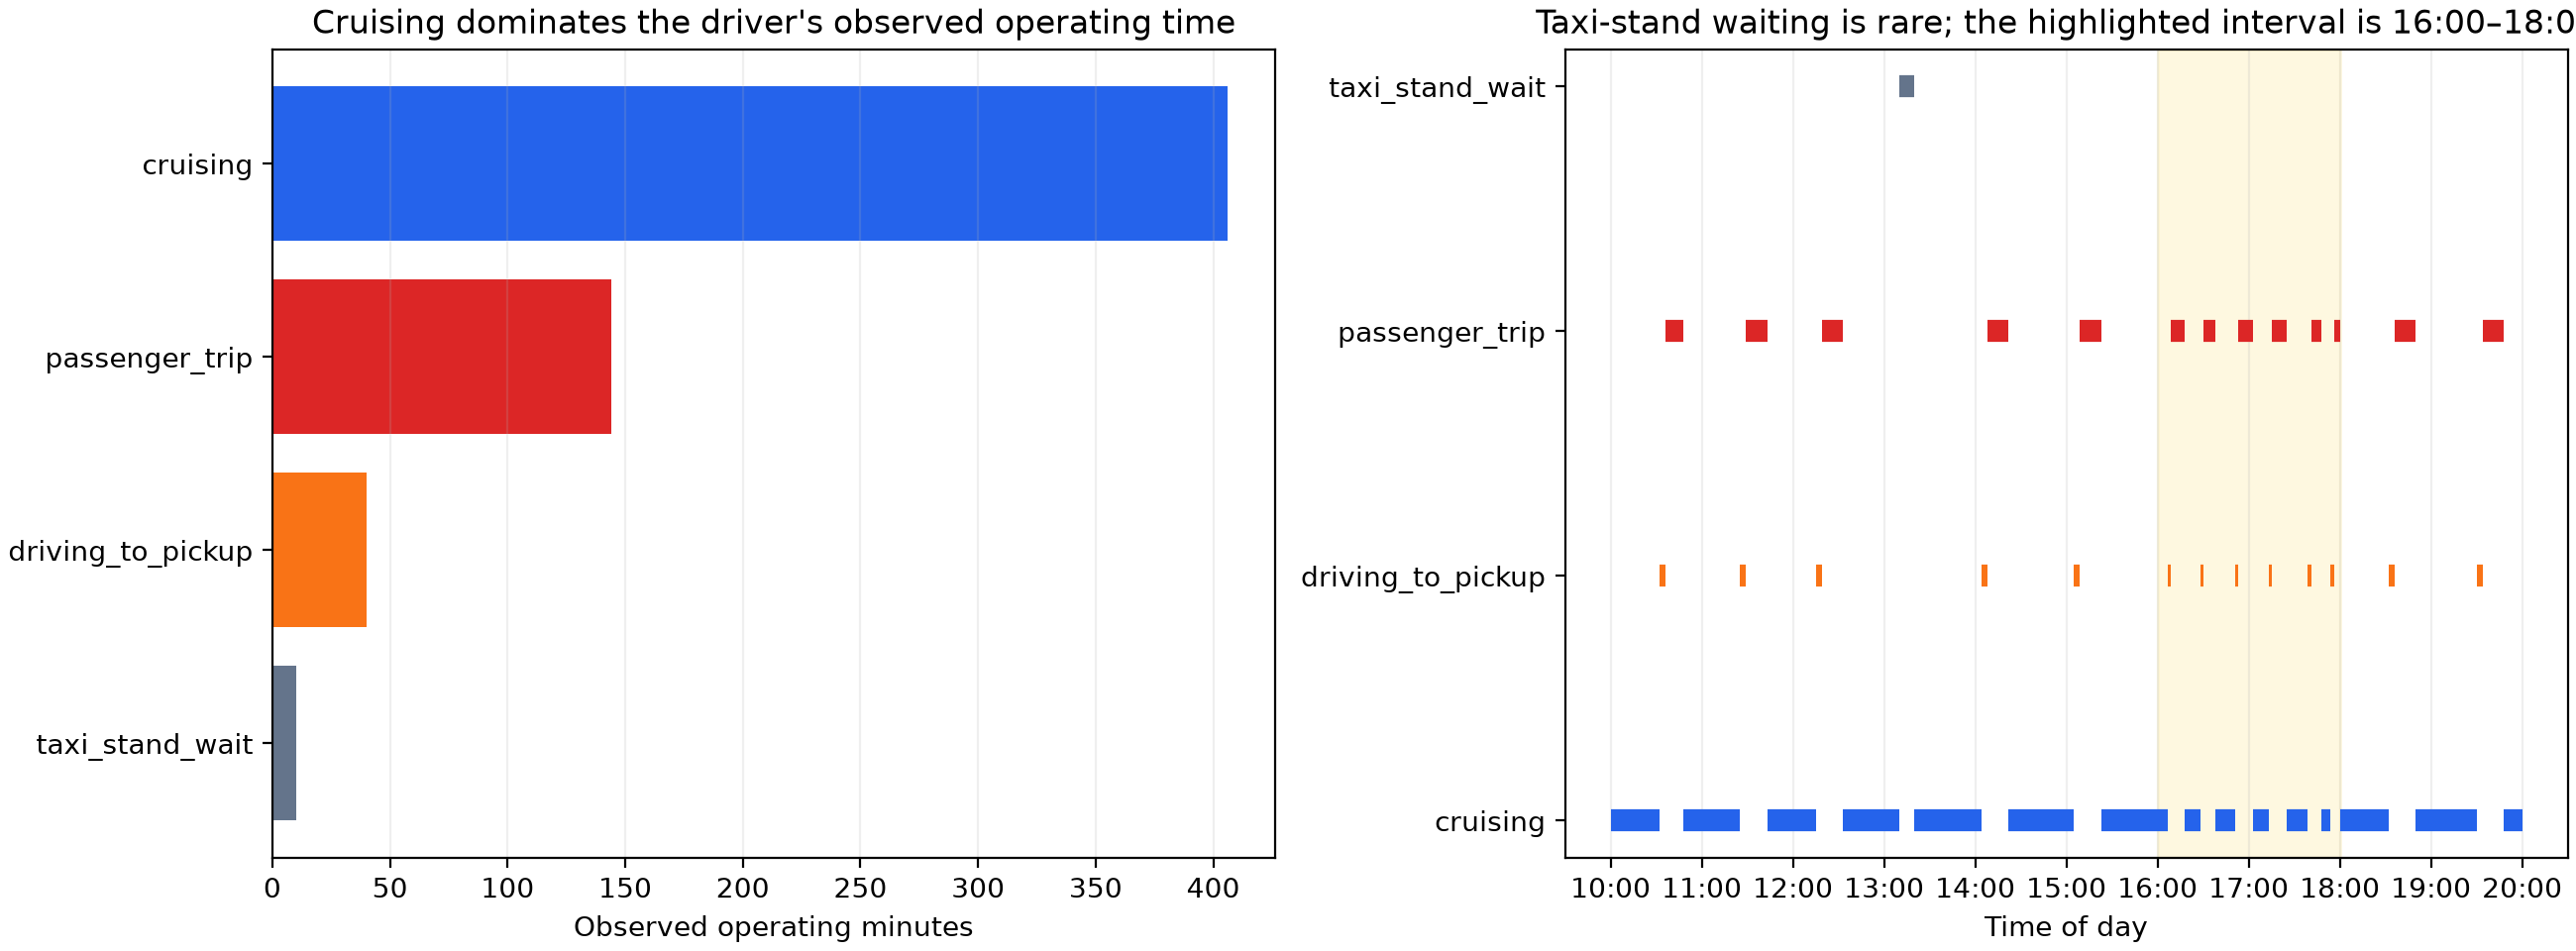

In [ ]:
d=df.copy(); print(d.groupby('operating_state').duration_min.sum())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/operating_time_allocation_and_timeline.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "operating_time_allocation",
  "insight": "The driver spends most observed operating time cruising around the city and spends very little time waiting at a taxi stand.",
  "plot": {
    "plot_type": "state_duration_bar_and_timeline",
    "file": "visualizations/operating_time_allocation_and_timeline.png",
    "title": "Operating-Time Allocation and Timeline",
    "description": "Cruising duration and the state timeline show that taxi-stand waiting occupies only a small part of the observed day."
  },
  "question": "How does the driver allocate observed operating time among cruising, taxi-stand waiting, pickup approach, and passenger service?",
  "code": "d=df.copy(); print(d.groupby('operating_state').duration_min.sum())",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "operating_state",
    "trajectory_timestamp",
    "gps_position",
    "driver_id"
  ]
}

### **Question 2**: Which request sources account for this driver’s completed orders, and where do the primary-source pickups occur relative to the cruising footprint?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

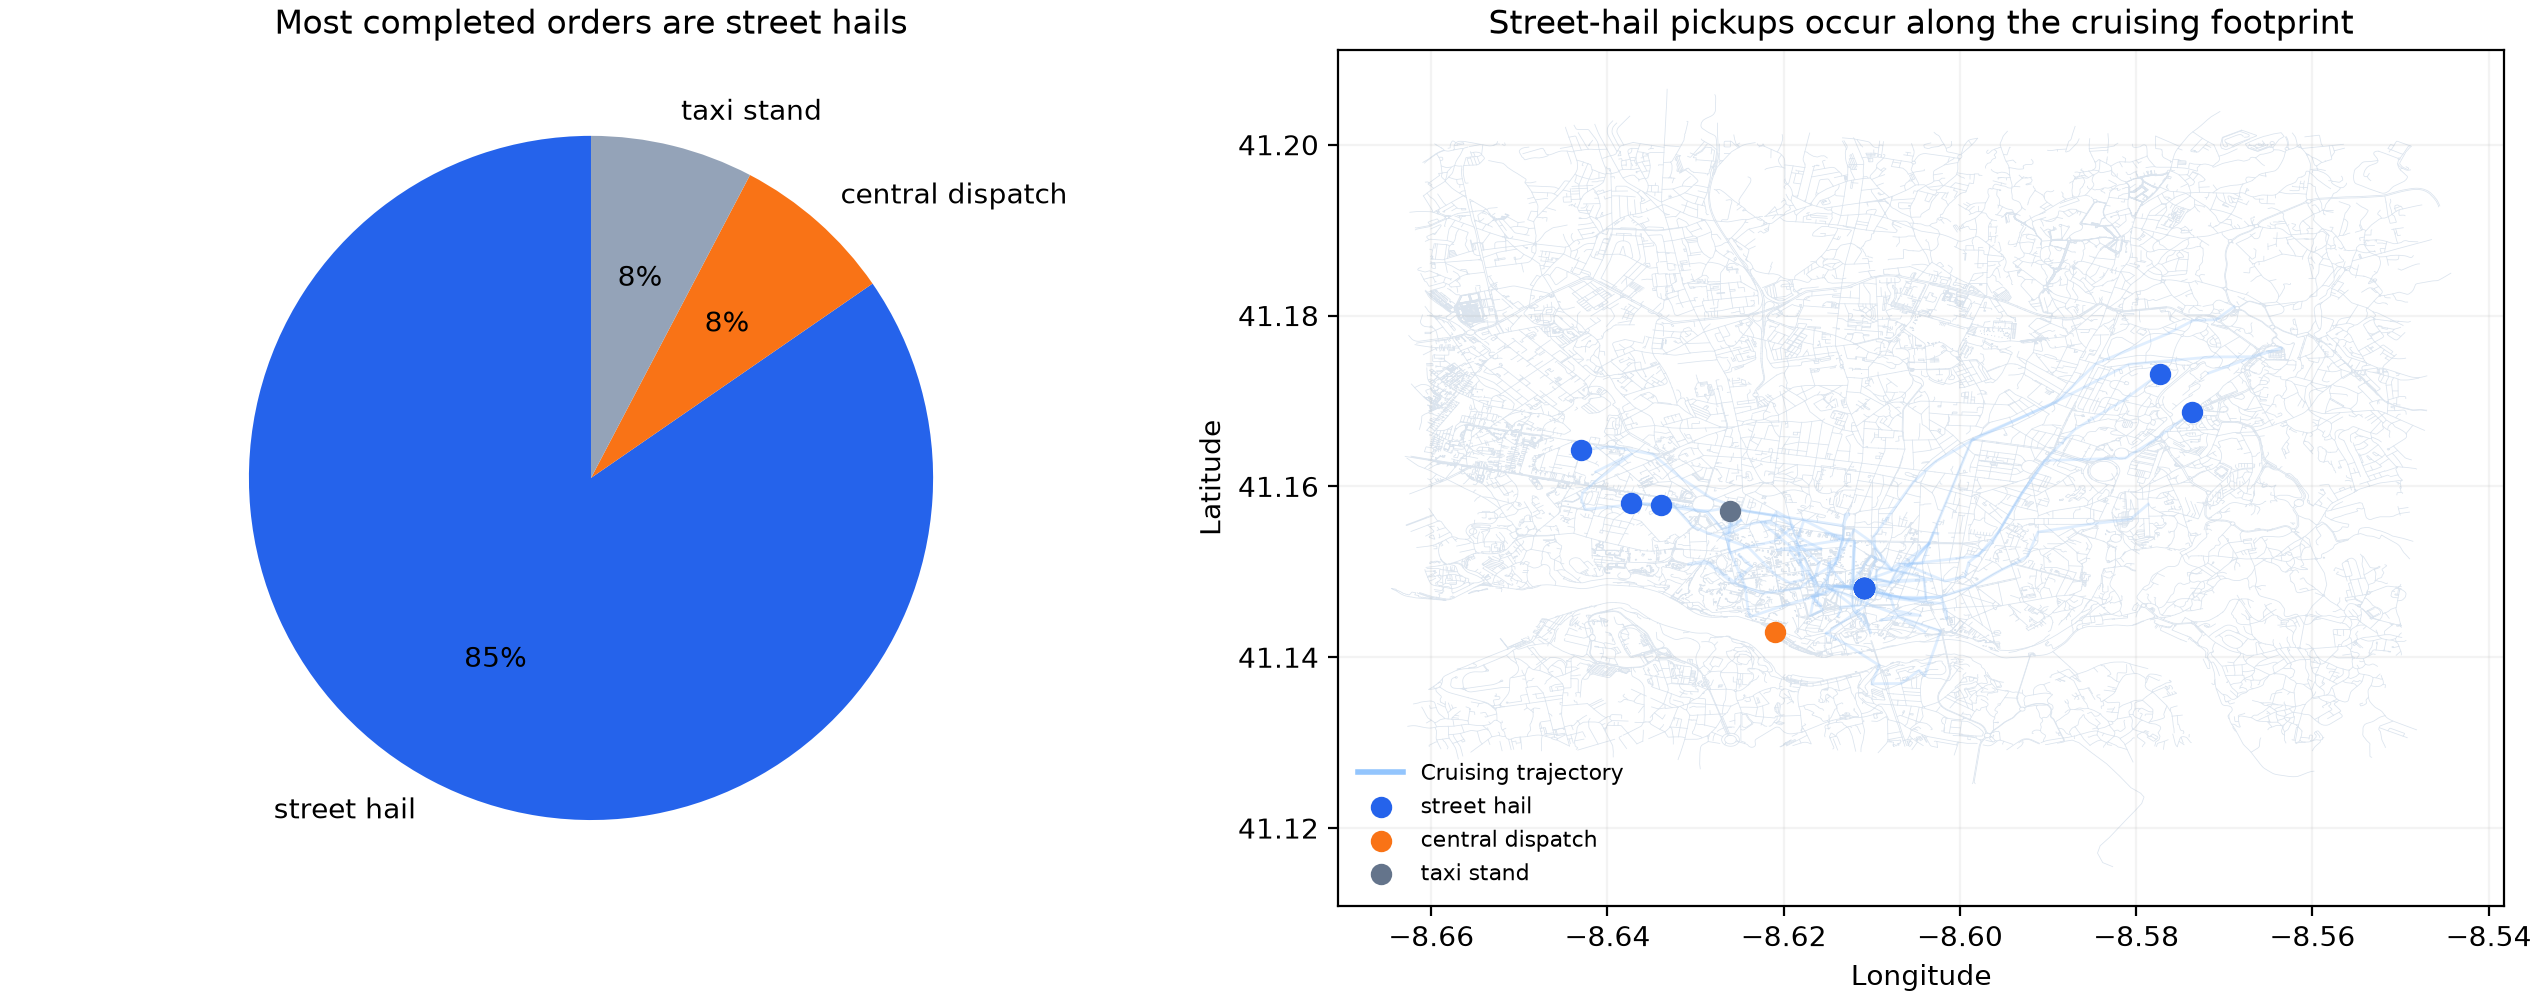

In [ ]:
o=pd.read_csv('orders.csv'); print(o.request_source.value_counts(normalize=True))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/street_hails_during_cruising.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "order_source_and_cruising_context",
  "insight": "Most of this driver's completed orders are street hails encountered while cruising through the city.",
  "plot": {
    "plot_type": "order_source_composition_and_cruising_map",
    "file": "visualizations/street_hails_during_cruising.png",
    "title": "Street Hails within the Cruising Footprint",
    "description": "Order-source composition is paired with pickup locations over the driver’s cruising trajectories."
  },
  "question": "Which request sources account for this driver’s completed orders, and where do the primary-source pickups occur relative to the cruising footprint?",
  "code": "o=pd.read_csv('orders.csv'); print(o.request_source.value_counts(normalize=True))",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "operating_state",
    "request_source",
    "trajectory_id",
    "gps_position",
    "driver_id",
    "trajectory_timestamp"
  ]
}

### **Question 3**: What repeated spatial and operational sequence does the driver follow from 16:00 to 18:00, and how does it differ from cruising at other times?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

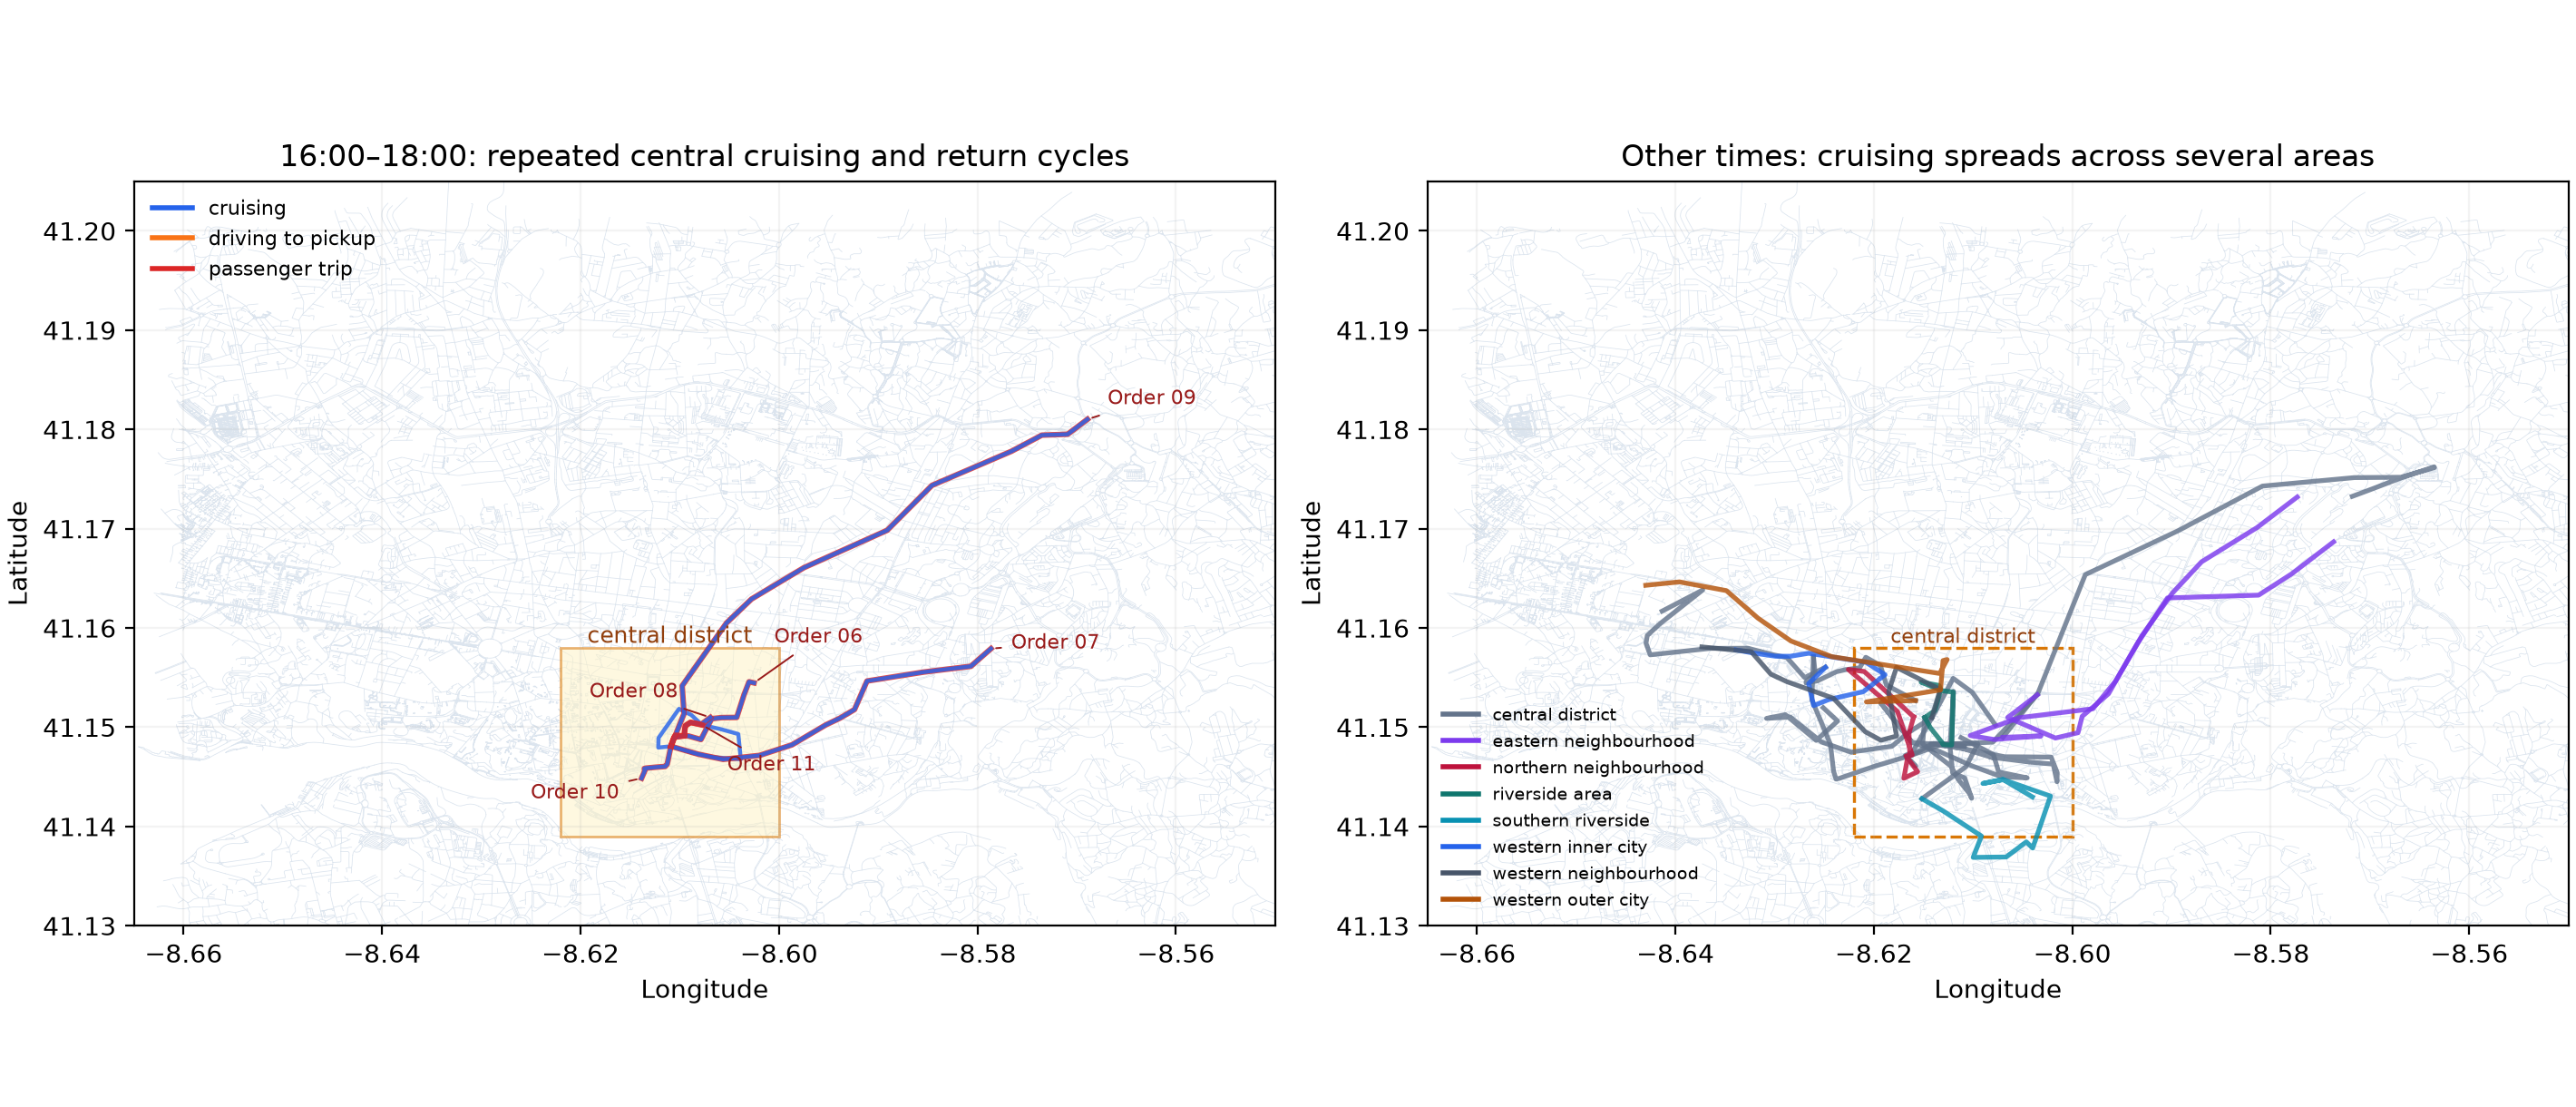

In [ ]:
d=df.copy(); d['start_time']=pd.to_datetime(d.start_time); print(d[(d.start_time.dt.hour>=16)&(d.start_time.dt.hour<18)][['operating_state','cruising_purpose','order_id','request_source']])
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/afternoon_central_cruising_cycles.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "afternoon_central_operating_sequence",
  "insight": "From 16:00 to 18:00, the driver repeatedly cruises in the central district, completes a trip after each order, then returns to the centre to cruise until the next order; most orders in this interval are street hails. Cruising locations are less fixed at other times.",
  "plot": {
    "plot_type": "time_filtered_state_colored_trajectory_map",
    "file": "visualizations/afternoon_central_cruising_cycles.png",
    "title": "16:00–18:00 Central Cruising Cycles",
    "description": "State-coloured trajectories show central cruising, street-hail service, and subsequent returns to the centre in chronological sequence."
  },
  "question": "What repeated spatial and operational sequence does the driver follow from 16:00 to 18:00, and how does it differ from cruising at other times?",
  "code": "d=df.copy(); d['start_time']=pd.to_datetime(d.start_time); print(d[(d.start_time.dt.hour>=16)&(d.start_time.dt.hour<18)][['operating_state','cruising_purpose','order_id','request_source']])",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "operating_state",
    "trajectory_timestamp",
    "gps_position",
    "request_source",
    "driver_id",
    "trajectory_id"
  ]
}

### **Question 4**: How does the driver’s speed while cruising compare with speed during pickup approach and passenger service?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

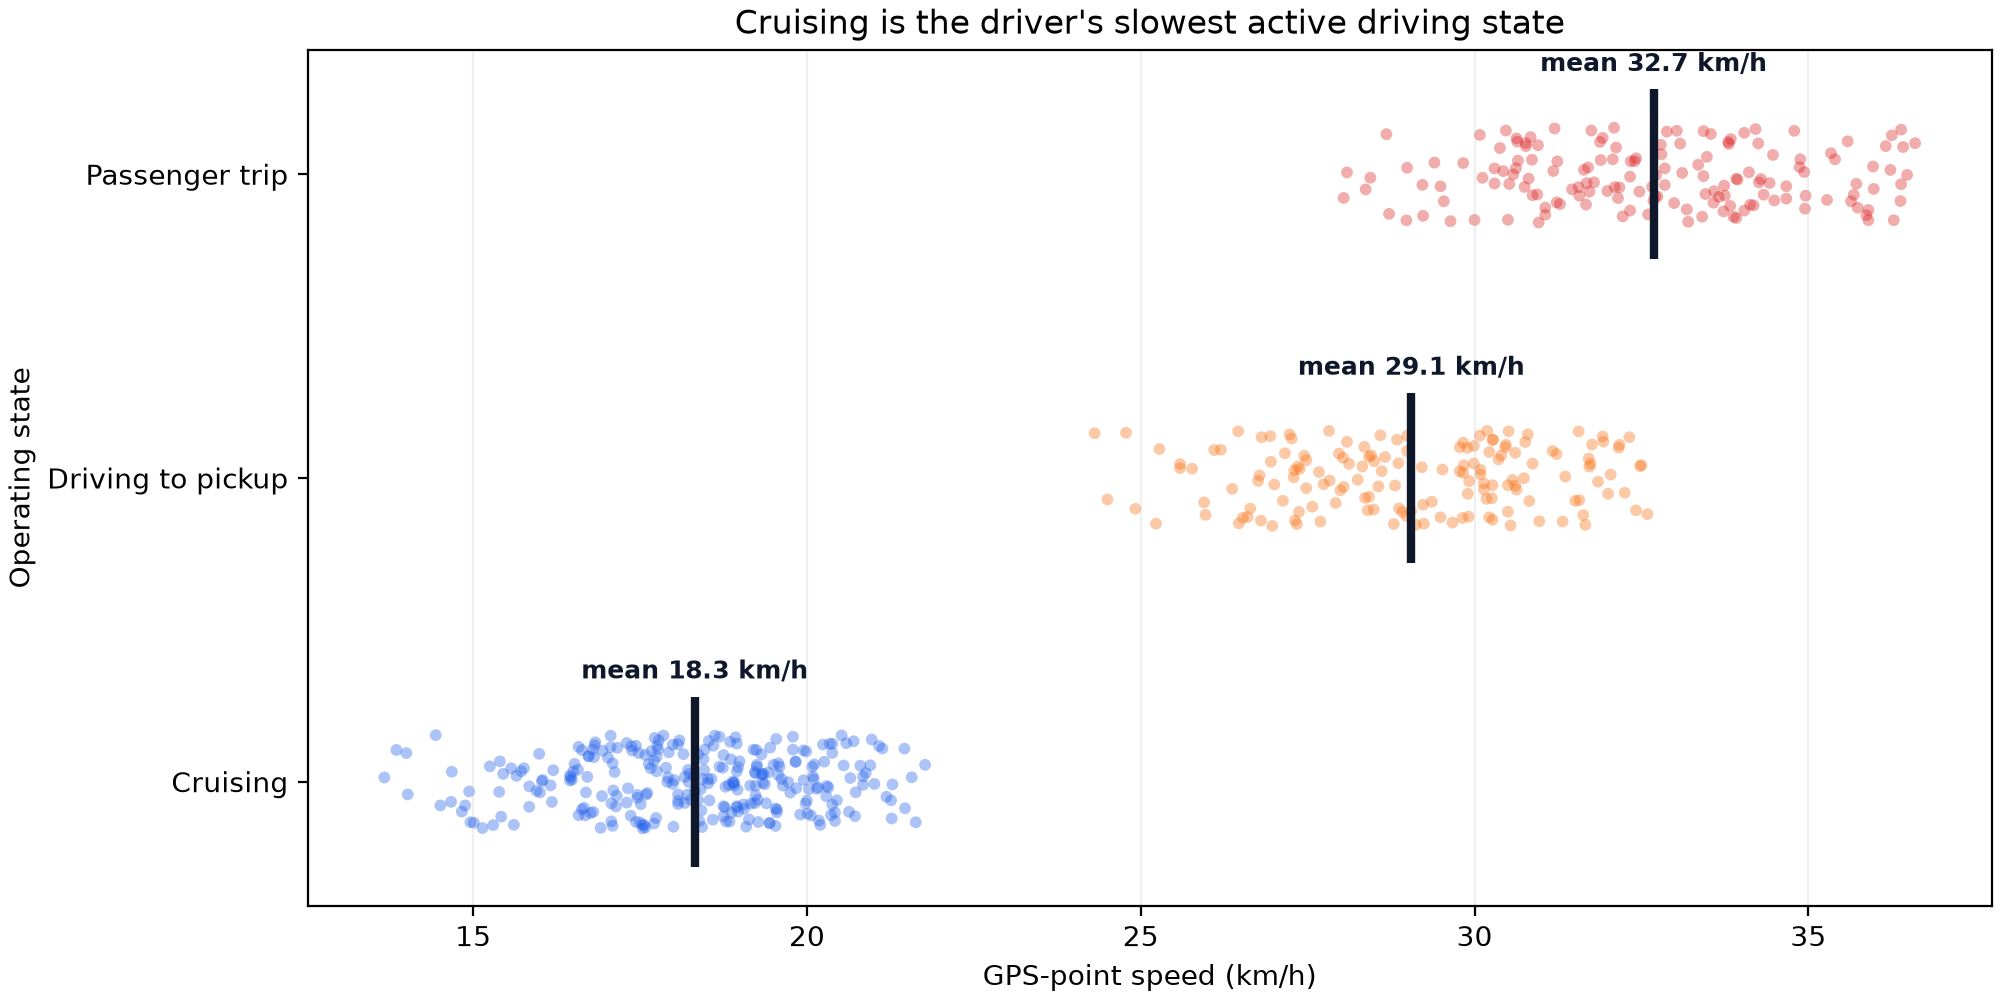

In [ ]:
p=pd.read_csv(user_dataset_path); print(p.groupby('operating_state').speed_kmh.describe())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/speed_by_operating_state.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "speed_by_operating_state",
  "insight": "The driver's cruising speed is lower than the speed while driving to a pickup or carrying a passenger.",
  "plot": {
    "plot_type": "operating_state_speed_ecdf",
    "file": "visualizations/speed_by_operating_state.png",
    "title": "Speed Distributions by Operating State",
    "description": "GPS-point speed distributions are compared for cruising, driving to pickup, and passenger service."
  },
  "question": "How does the driver’s speed while cruising compare with speed during pickup approach and passenger service?",
  "code": "p=pd.read_csv('trajectory_points.csv'); print(p.groupby('operating_state').speed_kmh.describe())",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "operating_state",
    "point_speed"
  ]
}

### Summary of Findings (Flag 8)

This driver mainly operates by cruising rather than waiting at taxi stands, and most completed orders are street hails. The 16:00–18:00 period is organized around repeated central-district cruising and return cycles after street-hail trips, while other cruising is spatially less fixed. Cruising is also the driver’s slowest active driving state.